# Modeling Human Activity States with Hidden Markov Models

**Use case:** elderly fall-risk and inactivity monitoring.

A Hidden Markov Model, implemented from scratch in NumPy, infers four hidden activity states (**still, standing, walking, jumping**) from smartphone accelerometer and gyroscope data.

**Sections**
1. Setup & data loading
2. Pre-processing & sampling-rate harmonisation
3. Feature extraction
4. HMM implementation
5. Model verification
6. Training
7. Evaluation on unseen data

## 1. Setup & Data Loading

Recordings were made with **Sensor Logger** (Android, Infinix X6855). Each export is a folder with one CSV per sensor. Each CSV has `time` (ns since the Unix epoch), `seconds_elapsed`, and the axes in the order `z, y, x`. A `Metadata.csv` file records the device and the configured sample rates.

Two streams are used:

| Stream | File | Units | Why |
|---|---|---|---|
| Accelerometer | `TotalAcceleration.csv` | m/s² | The true accelerometer reading, **including gravity**. The app's `Accelerometer.csv` has gravity removed, which would discard the orientation cue that separates *still* (phone flat) from *standing* (phone upright). |
| Gyroscope | `Gyroscope.csv` | rad/s | Calibrated angular velocity (bias-corrected). |

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

ROOT = Path.cwd().resolve().parent if Path.cwd().name == "notebooks" else Path.cwd().resolve()
RAW_DIR = ROOT / "data" / "raw"
PROCESSED_DIR = ROOT / "data" / "processed"
LABELS_DIR = ROOT / "data" / "labels"
FIG_DIR = ROOT / "figures"

ACTIVITIES = ["still", "standing", "walking", "jumping"]
SENSOR_FILES = {"acc": "TotalAcceleration.csv", "gyro": "Gyroscope.csv"}
TARGET_FS = 25  # Hz; common rate every recording is harmonised to (Section 2)

sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.precision", 3)

/home/hassan/.config/matplotlib is not a writable directory


Matplotlib created a temporary cache directory at /tmp/matplotlib-nq07lzy4 because there was an issue with the default path (/home/hassan/.config/matplotlib); it is highly recommended to set the MPLCONFIGDIR environment variable to a writable directory, in particular to speed up the import of Matplotlib and to better support multiprocessing.


### 1.1 Loading utilities

In [2]:
def load_metadata(rec_dir):
    """Read a recording's Metadata.csv.

    Returns a dict with the device, OS and app versions, the recording start
    (epoch, ns) and the configured sample rate in Hz for each stream in
    SENSOR_FILES.
    """
    meta = pd.read_csv(rec_dir / "Metadata.csv").iloc[0]
    rate_ms = dict(zip(meta["sensors"].split("|"), str(meta["sampleRateMs"]).split("|")))
    configured_hz = {
        key: 1000 / float(rate_ms[fname.removesuffix(".csv")])
        for key, fname in SENSOR_FILES.items()
    }
    return {
        "device": meta["device name"],
        "platform": f'{meta["platform"]} {meta["platform version"]}',
        "app_version": str(meta["appVersion"]),
        "recorded_at": meta["recording time"],
        "epoch_ns": int(meta["recording epoch time"]) * 1_000_000,
        "configured_hz": configured_hz,
    }


def load_sensor(rec_dir, sensor, epoch_ns):
    """Load one sensor stream of a recording.

    Parameters
    ----------
    rec_dir : Path
        Folder of one exported recording.
    sensor : str
        Key of SENSOR_FILES ("acc" or "gyro").
    epoch_ns : int
        Recording start (ns), so every stream of a recording shares one time origin.

    Returns
    -------
    DataFrame with columns timestamp_ns, t (s since recording start), x, y, z,
    sorted by time with duplicate timestamps removed.
    """
    df = pd.read_csv(rec_dir / SENSOR_FILES[sensor])
    df = df.sort_values("time").drop_duplicates("time")
    return pd.DataFrame({
        "timestamp_ns": df["time"].to_numpy(),
        "t": (df["time"].to_numpy() - epoch_ns) / 1e9,
        "x": df["x"].to_numpy(),
        "y": df["y"].to_numpy(),
        "z": df["z"].to_numpy(),
    })


def load_recording(rec_dir):
    """Load metadata plus the accelerometer and gyroscope streams of one recording."""
    rec_dir = Path(rec_dir)
    meta = load_metadata(rec_dir)
    rec = {"name": rec_dir.name, "meta": meta}
    for sensor in SENSOR_FILES:
        rec[sensor] = load_sensor(rec_dir, sensor, meta["epoch_ns"])
    return rec


def sampling_stats(df):
    """Measured sampling statistics of one stream.

    The measured rate is 1 / median(dt). "Dropped" counts intervals longer than
    1.5x the median (at least one missing sample). "Large gaps" counts intervals
    longer than 3x the median, which would need attention during cleaning.
    """
    dt = np.diff(df["t"].to_numpy())
    med = np.median(dt)
    return {
        "n_samples": len(df),
        "duration_s": df["t"].iloc[-1] - df["t"].iloc[0],
        "measured_hz": 1 / med,
        "median_dt_ms": med * 1e3,
        "jitter_ms": dt.std() * 1e3,
        "max_dt_ms": dt.max() * 1e3,
        "dropped": int((dt > 1.5 * med).sum()),
        "large_gaps": int((dt > 3 * med).sum()),
    }

### 1.2 Pilot check

Before the main collection, four short pilot recordings were made to check the data format:

| Pilot | Phone | Question it answers |
|---|---|---|
| `pilot_01_flat` | Flat on a table | Is gravity included? Which axis carries it when flat? |
| `pilot_02_upright` | Held at waist level (the grip used for standing, walking, jumping) | Which axis carries gravity when upright? |
| `pilot_03_walk` | Same grip, walking | Data quality during movement |
| `pilot_04_flat_50hz` | Flat, app set to a lower rate | Does the rate setting change the delivered rate? |

In [3]:
pilots = [load_recording(p) for p in sorted((RAW_DIR / "pilot").iterdir()) if p.is_dir()]

print(f"Device: {pilots[0]['meta']['device']}  |  {pilots[0]['meta']['platform']}  |  Sensor Logger {pilots[0]['meta']['app_version']}")
pilot_rates = pd.DataFrame([
    {"recording": rec["name"], "sensor": sensor,
     "configured_hz": rec["meta"]["configured_hz"][sensor], **sampling_stats(rec[sensor])}
    for rec in pilots for sensor in SENSOR_FILES
]).set_index(["recording", "sensor"])
pilot_rates

Device: Infinix X6855  |  android 36  |  Sensor Logger 1.68


configured_hz  n_samples  duration_s  measured_hz  \
recording          sensor                                                      
pilot_01_flat      acc             100.0        574       9.804       58.445   
                   gyro            100.0        575       9.825       58.445   
pilot_02_upright   acc             100.0        736      12.575       58.448   
                   gyro            100.0        739      12.635       58.448   
pilot_03_walk      acc             100.0        898      15.342       58.452   
                   gyro            100.0        897      15.329       58.452   
pilot_04_flat_50hz acc              50.0        528      18.031       29.227   
                   gyro             50.0        529      18.066       29.227   

                           median_dt_ms  jitter_ms  max_dt_ms  dropped  \
recording          sensor                                                
pilot_01_flat      acc           17.110  1.517e-04     17.110        0   
                   gyro          17.110  1.784e-01     21.387        0   
pilot_02_upright   acc           17.109  1.330e-04     17.110        0   
                   gyro          17.109  3.147e-01     25.664        0   
pilot_03_walk      acc           17.108  1.427e-01     17.109        0   
                   gyro          17.108  1.627e-04     17.109        0   
pilot_04_flat_50hz acc           34.215  1.718e-04     34.216        0   
                   gyro          34.215  1.809e-04     34.216        0   

                           large_gaps  
recording          sensor              
pilot_01_flat      acc              0  
                   gyro             0  
pilot_02_upright   acc              0  
                   gyro             0  
pilot_03_walk      acc              0  
                   gyro             0  
pilot_04_flat_50hz acc              0  
                   gyro             0

In [4]:
def stream_offset_ms(rec):
    """Start-time difference between the gyroscope and accelerometer streams (ms)."""
    return (rec["gyro"]["t"].iloc[0] - rec["acc"]["t"].iloc[0]) * 1e3


def shared_timestamps(rec):
    """Fraction of accelerometer timestamps that also appear in the gyroscope stream."""
    return np.isin(rec["acc"]["timestamp_ns"], rec["gyro"]["timestamp_ns"]).mean()


pd.DataFrame([
    {"recording": rec["name"], "gyro_start_offset_ms": stream_offset_ms(rec),
     "shared_timestamps": shared_timestamps(rec)}
    for rec in pilots
]).set_index("recording")

,gyro_start_offset_ms,shared_timestamps
recording,,
pilot_01_flat,-17.110,0.0
pilot_02_upright,-17.109,0.0
pilot_03_walk,17.108,0.0
pilot_04_flat_50hz,-17.108,0.0


In [5]:
def steady(df, trim_s=1.0):
    """Drop the first and last trim_s seconds (button-press and settling artefacts)."""
    t = df["t"]
    return df[(t > t.iloc[0] + trim_s) & (t < t.iloc[-1] - trim_s)]


def magnitude(df):
    """Euclidean norm of the x, y, z columns."""
    return np.sqrt(df["x"] ** 2 + df["y"] ** 2 + df["z"] ** 2)


orientation = pd.DataFrame([
    {"recording": rec["name"],
     **{f"mean_acc_{ax}": steady(rec["acc"])[ax].mean() for ax in "xyz"},
     "mean_|a|": magnitude(steady(rec["acc"])).mean(),
     "std_|a|": magnitude(steady(rec["acc"])).std(),
     "std_|w|": magnitude(steady(rec["gyro"])).std()}
    for rec in pilots
]).set_index("recording")
orientation

,mean_acc_x,mean_acc_y,mean_acc_z,mean_|a|,std_|a|,std_|w|
recording,,,,,,
pilot_01_flat,-0.081,0.578,9.819,9.836,0.007,4.311e-04
pilot_02_upright,0.369,9.843,1.286,9.944,0.142,1.044e-01
pilot_03_walk,0.299,9.857,1.094,9.992,0.852,4.798e-01
pilot_04_flat_50hz,-0.137,0.502,9.826,9.840,0.048,6.309e-03


### 1.3 Pilot findings

- **Gravity.** `TotalAcceleration` has |a| ≈ 9.8 m/s² at rest, so it includes gravity and is used as the accelerometer.
- **Orientation separates still from standing.** Flat on the table, gravity lies on **z** (≈ 9.8 m/s²). In the waist-level grip it lies on **y** (≈ 9.7 m/s², z ≈ 1.3). The per-axis means of the accelerometer are therefore strong features for still vs standing.
- **Delivered rate ≠ configured rate.** A configured 100 Hz delivers **≈ 58.4 Hz** (17.1 ms). The lower setting (50 Hz) delivers **≈ 29.2 Hz** (34.2 ms). The phone snaps requests to its own supported rates.
- **Timing quality.** Sampling is very regular: jitter σ ≤ 0.3 ms, no dropped samples and no gaps. The gyroscope has a few slightly long intervals (up to ~26 ms).
- **Streams are not aligned.** The accelerometer and gyroscope are sampled at different instants (**no shared timestamps**) and start up to one sample period (~17 ms) apart, so the two streams cannot be joined row by row. Both are interpolated onto one common time grid instead.

**Consequence for harmonisation (Section 2).** Recordings exist at two real rates (58.4 Hz and 29.2 Hz). All streams are low-pass filtered (anti-aliasing) and resampled onto a common **25 Hz** grid. 25 Hz sits just below the lowest delivered rate, so every recording is *downsampled*; nothing is upsampled. The resulting Nyquist frequency of 12.5 Hz still covers the walking and jumping fundamentals (~1.5–2.5 Hz) and their main harmonics.

## 2. Pre-processing & Sampling-Rate Harmonisation

Recordings were made at a configured 100 Hz, which delivered **≈ 58.5 Hz** (the phone snaps to its own supported rate). The accelerometer and gyroscope run on **separate clocks** with **no shared timestamps**, so every recording is:

1. **Anti-alias filtered** (Butterworth order 4, cutoff 10 Hz — below the new 12.5 Hz Nyquist).
2. **Resampled** onto a **uniform 25 Hz** grid via linear interpolation.

25 Hz sits below the lowest delivered rate (≈ 29.2 Hz from the 50 Hz setting used in the pilot), so every recording is strictly *downsampled*. The 12.5 Hz Nyquist still covers walking (≈ 1.6–2 steps/s) and jumping (≈ 1.5–2.5 jumps/s) fundamentals plus their main harmonics.

### 2.1 Load all training recordings

In [6]:
# Load clips
clips = []
for activity in ACTIVITIES:
    clips_dir = RAW_DIR / "clips" / activity
    for clip_dir in sorted(clips_dir.iterdir()):
        if not clip_dir.is_dir() or clip_dir.name.startswith("."):
            continue
        rec = load_recording(clip_dir)
        rec["activity"] = activity
        rec["rec_type"] = "clip"
        clips.append(rec)

# Load sessions
sessions = []
for sess_dir in sorted((RAW_DIR / "sessions").iterdir()):
    if not sess_dir.is_dir() or sess_dir.name.startswith("."):
        continue
    rec = load_recording(sess_dir)
    rec["activity"] = "mixed"
    rec["rec_type"] = "session"
    sessions.append(rec)

all_recs = clips + sessions
print(f"Loaded {len(clips)} clips + {len(sessions)} sessions = {len(all_recs)} recordings")

Loaded 52 clips + 2 sessions = 54 recordings


### 2.2 Sampling quality checks

In [7]:
quality_rows = []
for rec in all_recs:
    for sensor in SENSOR_FILES:
        stats = sampling_stats(rec[sensor])
        quality_rows.append({
            "recording": rec["name"],
            "type": rec["rec_type"],
            "activity": rec["activity"],
            "sensor": sensor,
            **stats,
        })

qdf = pd.DataFrame(quality_rows)

# Summary by type and sensor
print("Rate summary (clips only, acc):")
clip_acc = qdf[(qdf["type"] == "clip") & (qdf["sensor"] == "acc")]
print(f"  Measured Hz: {clip_acc['measured_hz'].min():.1f}"
      f"–{clip_acc['measured_hz'].max():.1f} "
      f"(median dt = {clip_acc['median_dt_ms'].median():.1f} ms)")
print(f"  Max jitter: {clip_acc['jitter_ms'].max():.2f} ms")
print(f"  Any large gaps: {(clip_acc['large_gaps'] > 0).sum()} recordings")

# Flag session issues
sess_q = qdf[qdf["type"] == "session"]
print("\nSession quality:")
for _, row in sess_q.iterrows():
    flag = " ⚠ GAPS" if row["large_gaps"] > 0 else ""
    print(f"  {row['recording']} {row['sensor']}: "
          f"{row['measured_hz']:.1f} Hz, "
          f"duration {row['duration_s']:.1f}s, "
          f"{row['n_samples']} samples{flag}")

Rate summary (clips only, acc):
  Measured Hz: 58.4–58.5 (median dt = 17.1 ms)
  Max jitter: 0.18 ms
  Any large gaps: 0 recordings

Session quality:
  train_session_01 acc: 58.5 Hz, duration 137.8s, 7391 samples ⚠ GAPS
  train_session_01 gyro: 58.5 Hz, duration 137.8s, 7391 samples ⚠ GAPS
  train_session_02 acc: 58.5 Hz, duration 114.0s, 1547 samples ⚠ GAPS
  train_session_02 gyro: 58.5 Hz, duration 114.0s, 1548 samples ⚠ GAPS


### 2.3 Resampling functions

In [8]:
from scipy.signal import butter, filtfilt


def resample_uniform(df, target_fs, cutoff_hz=10.0, filter_order=4):
    """Anti-alias low-pass filter then interpolate onto a uniform time grid.

    Parameters
    ----------
    df : DataFrame with columns t, x, y, z
    target_fs : target sampling rate (Hz)
    cutoff_hz : Butterworth cutoff (Hz), must be < target_fs / 2
    filter_order : Butterworth order

    Returns
    -------
    DataFrame with uniform dt = 1/target_fs.
    """
    t = df["t"].to_numpy()
    source_fs = 1.0 / np.median(np.diff(t))

    # Butterworth anti-alias filter (zero-phase)
    b, a = butter(filter_order, cutoff_hz / (source_fs / 2), btype="low")

    t_uniform = np.arange(t[0], t[-1], 1.0 / target_fs)
    result = {"t": t_uniform}
    for axis in ("x", "y", "z"):
        filtered = filtfilt(b, a, df[axis].to_numpy())
        result[axis] = np.interp(t_uniform, t, filtered)
    return pd.DataFrame(result)


def harmonise_recording(rec, target_fs=TARGET_FS, cutoff_hz=10.0):
    """Resample both sensor streams onto one common uniform grid.

    The grid covers only the time range where *both* sensors have data,
    so no extrapolation occurs.
    """
    acc_rs = resample_uniform(rec["acc"], target_fs, cutoff_hz)
    gyro_rs = resample_uniform(rec["gyro"], target_fs, cutoff_hz)

    t_start = max(acc_rs["t"].iloc[0], gyro_rs["t"].iloc[0])
    t_end = min(acc_rs["t"].iloc[-1], gyro_rs["t"].iloc[-1])
    t_grid = np.arange(t_start, t_end, 1.0 / target_fs)

    out = pd.DataFrame({"t": t_grid})
    for axis in ("x", "y", "z"):
        out[f"acc_{axis}"] = np.interp(
            t_grid, acc_rs["t"].to_numpy(), acc_rs[axis].to_numpy()
        )
        out[f"gyro_{axis}"] = np.interp(
            t_grid, gyro_rs["t"].to_numpy(), gyro_rs[axis].to_numpy()
        )
    return out

### 2.4 Apply harmonisation to all recordings

In [9]:
harmonised = {}
for rec in all_recs:
    harmonised[rec["name"]] = harmonise_recording(rec)

# Verify uniform sampling on a few recordings
for name in list(harmonised)[:3]:
    df = harmonised[name]
    dt = np.diff(df["t"].to_numpy())
    print(f"{name}: {len(df)} samples, "
          f"dt = {np.median(dt)*1000:.1f} ms "
          f"(min {dt.min()*1000:.1f}, max {dt.max()*1000:.1f})")

still_01: 376 samples, dt = 40.0 ms (min 40.0, max 40.0)
still_02: 361 samples, dt = 40.0 ms (min 40.0, max 40.0)
still_03: 331 samples, dt = 40.0 ms (min 40.0, max 40.0)


### 2.5 Trim clips & label sessions

Each clip is trimmed by 1 s on each end to remove button-press artefacts. Session labels are expanded from the segment tables in `data/labels/`.

In [10]:
TRIM_S = 1.0  # seconds trimmed from each end of every clip


def trim_clip(df, trim_s=TRIM_S):
    """Remove trim_s seconds from each end of a harmonised clip."""
    t = df["t"].to_numpy()
    mask = (t >= t[0] + trim_s) & (t <= t[-1] - trim_s)
    return df[mask].reset_index(drop=True)


def label_session(df, label_file):
    """Assign per-row activity labels from a segment table.

    Parameters
    ----------
    df : harmonised DataFrame with column 't'
    label_file : CSV with columns start_s, end_s, activity

    Returns
    -------
    DataFrame with an 'activity' column; rows outside all segments
    are dropped.
    """
    segments = pd.read_csv(label_file)
    t = df["t"].to_numpy()
    labels = np.full(len(df), "", dtype=object)
    for _, row in segments.iterrows():
        labels[(t >= row["start_s"]) & (t < row["end_s"])] = row["activity"]
    out = df.copy()
    out["activity"] = labels
    return out[out["activity"] != ""].reset_index(drop=True)


# ── Process clips ──
processed_clips = []
for rec in clips:
    name = rec["name"]
    trimmed = trim_clip(harmonised[name])
    trimmed = trimmed.copy()
    trimmed["activity"] = rec["activity"]
    dur = trimmed["t"].iloc[-1] - trimmed["t"].iloc[0]
    processed_clips.append({
        "name": name, "activity": rec["activity"],
        "df": trimmed, "duration": dur,
    })

# ── Process sessions ──
processed_sessions = []
for rec in sessions:
    name = rec["name"]
    lf = LABELS_DIR / f"{name}.csv"
    if not lf.exists():
        print(f"Skipping {name}: no label file")
        continue
    labelled = label_session(harmonised[name], lf)
    processed_sessions.append({"name": name, "df": labelled})
    counts = labelled["activity"].value_counts().to_dict()
    print(f"{name}: {len(labelled)} samples, labels = {counts}")

print(f"\nProcessed: {len(processed_clips)} clips, "
      f"{len(processed_sessions)} sessions")

train_session_01: 3444 samples, labels = {'walking': 1425, 'standing': 950, 'still': 819, 'jumping': 250}
Skipping train_session_02: no label file

Processed: 52 clips, 1 sessions


### 2.6 Duration verification

In [11]:
dur_per_activity = {a: 0.0 for a in ACTIVITIES}

for pc in processed_clips:
    dur_per_activity[pc["activity"]] += pc["duration"]

for ps in processed_sessions:
    for activity in ACTIVITIES:
        n = (ps["df"]["activity"] == activity).sum()
        dur_per_activity[activity] += n / TARGET_FS

print("Activity durations (clips + sessions):")
for activity in ACTIVITIES:
    s = "✓" if dur_per_activity[activity] >= 90 else "✗ BELOW 90s"
    print(f"  {activity:10s}: {dur_per_activity[activity]:6.0f}s  {s}")

Activity durations (clips + sessions):
  still     :    208s  ✓
  standing  :    176s  ✓
  walking   :    193s  ✓
  jumping   :    143s  ✓


### 2.7 Save processed CSVs

In [12]:
def save_processed(df, out_path):
    """Save a harmonised, labelled DataFrame with the project schema.

    Schema: timestamp_ns, seconds_elapsed, acc_x..z, gyro_x..z, activity
    """
    out = pd.DataFrame()
    t = df["t"].to_numpy()
    out["timestamp_ns"] = (t * 1e9).astype(np.int64)
    out["seconds_elapsed"] = t - t[0]
    for col in ["acc_x", "acc_y", "acc_z",
                 "gyro_x", "gyro_y", "gyro_z"]:
        out[col] = df[col].to_numpy()
    out["activity"] = df["activity"].to_numpy()
    out.to_csv(out_path, index=False)
    return out_path


clips_out = PROCESSED_DIR / "train" / "clips"
clips_out.mkdir(parents=True, exist_ok=True)
for pc in processed_clips:
    save_processed(pc["df"], clips_out / f'{pc["name"]}.csv')

sessions_out = PROCESSED_DIR / "train" / "sessions"
sessions_out.mkdir(parents=True, exist_ok=True)
for ps in processed_sessions:
    save_processed(ps["df"], sessions_out / f'{ps["name"]}.csv')

# Verify
n_clips = len(list(clips_out.glob("*.csv")))
n_sess = len(list(sessions_out.glob("*.csv")))
print(f"Saved {n_clips} clips + {n_sess} sessions to data/processed/train/")

# Spot-check
check = pd.read_csv(clips_out / "standing_01.csv")
dt_c = np.diff(check["seconds_elapsed"].to_numpy())
print(f"\nSpot-check standing_01.csv: "
      f"{check.shape[0]} rows, "
      f"dt = {np.median(dt_c)*1000:.1f} ms, "
      f"NaNs = {check.isna().sum().sum()}, "
      f"duration = {check['seconds_elapsed'].iloc[-1]:.1f}s")

Saved 52 clips + 1 sessions to data/processed/train/

Spot-check standing_01.csv: 286 rows, dt = 40.0 ms, NaNs = 0, duration = 11.4s


### 2.8 Visualisations

**Fig. 1** (for the report): accelerometer and gyroscope magnitude for one representative clip per activity.

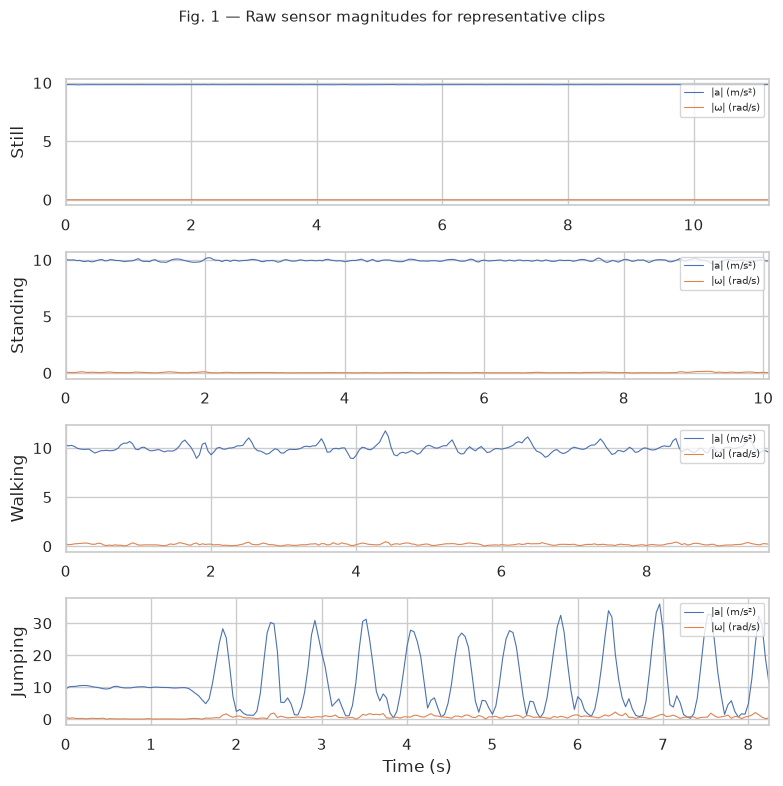

Saved to /home/hassan/dev/projects/coursework/hmm-elderly-activity-monitoring/figures/fig1_raw_signals.png


In [13]:
def acc_mag(df):
    """Accelerometer magnitude |a| from a processed DataFrame."""
    return np.sqrt(df["acc_x"]**2 + df["acc_y"]**2 + df["acc_z"]**2)

def gyro_mag(df):
    """Gyroscope magnitude |w| from a processed DataFrame."""
    return np.sqrt(df["gyro_x"]**2 + df["gyro_y"]**2 + df["gyro_z"]**2)


# ── Fig. 1: one representative clip per activity ──
fig, axes = plt.subplots(4, 1, figsize=(8, 8), sharex=False)
rep_clips = {
    "still": "still_03", "standing": "standing_03",
    "walking": "walking_03", "jumping": "jumping_03",
}

for ax, activity in zip(axes, ACTIVITIES):
    name = rep_clips[activity]
    pc = next(p for p in processed_clips if p["name"] == name)
    df = pc["df"]
    t = df["t"] - df["t"].iloc[0]
    ax.plot(t, acc_mag(df), label="|a| (m/s²)", linewidth=0.8)
    ax.plot(t, gyro_mag(df), label="|ω| (rad/s)", linewidth=0.8)
    ax.set_ylabel(activity.capitalize())
    ax.legend(loc="upper right", fontsize=7)
    ax.set_xlim(0, t.iloc[-1])

axes[-1].set_xlabel("Time (s)")
fig.suptitle(
    "Fig. 1 — Raw sensor magnitudes for representative clips",
    fontsize=11, y=0.98,
)
fig.tight_layout(rect=[0, 0, 1, 0.96])
fig.savefig(FIG_DIR / "fig1_raw_signals.png", dpi=200, bbox_inches="tight")
plt.show()
print(f"Saved to {FIG_DIR / 'fig1_raw_signals.png'}")

**Notebook-only figure:** Δt distribution before and after resampling.

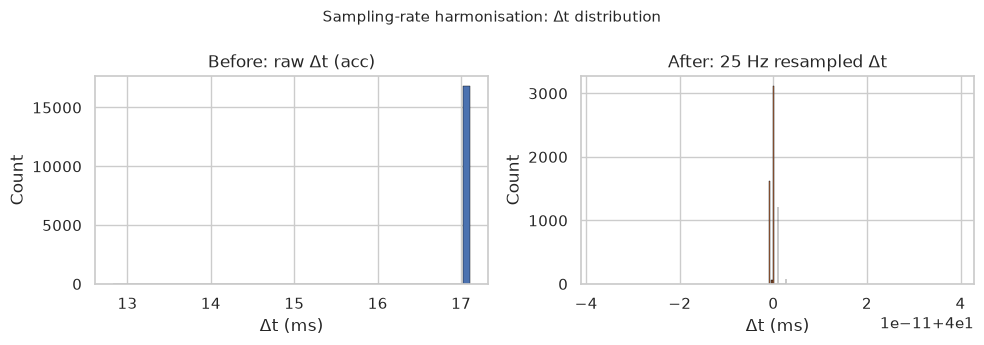

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))

# Before (raw)
all_dt_raw = []
for rec in clips[:20]:
    dt_raw = np.diff(rec["acc"]["t"].to_numpy()) * 1000
    all_dt_raw.extend(dt_raw)
axes[0].hist(all_dt_raw, bins=50, edgecolor="black", linewidth=0.3)
axes[0].set_title("Before: raw Δt (acc)")
axes[0].set_xlabel("Δt (ms)")
axes[0].set_ylabel("Count")

# After (resampled)
all_dt_rs = []
for pc in processed_clips[:20]:
    dt_rs = np.diff(pc["df"]["t"].to_numpy()) * 1000
    all_dt_rs.extend(dt_rs)
axes[1].hist(
    all_dt_rs, bins=50, edgecolor="black",
    linewidth=0.3, color="C1",
)
axes[1].set_title("After: 25 Hz resampled Δt")
axes[1].set_xlabel("Δt (ms)")
axes[1].set_ylabel("Count")

fig.suptitle("Sampling-rate harmonisation: Δt distribution", fontsize=11)
fig.tight_layout()
plt.show()

**Notebook-only figure:** total seconds per activity (clips + sessions), with the 90 s minimum line.

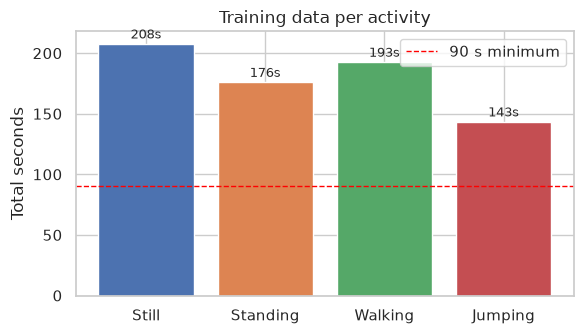

In [15]:
fig, ax = plt.subplots(figsize=(6, 3.5))
act_names = [a.capitalize() for a in ACTIVITIES]
act_durs = [dur_per_activity[a] for a in ACTIVITIES]
bars = ax.bar(act_names, act_durs, color=["C0", "C1", "C2", "C3"])
ax.axhline(90, color="red", linestyle="--", linewidth=1, label="90 s minimum")
ax.set_ylabel("Total seconds")
ax.set_title("Training data per activity")
ax.legend()
for bar, d in zip(bars, act_durs):
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 2,
        f"{d:.0f}s", ha="center", va="bottom", fontsize=9,
    )
fig.tight_layout()
plt.show()

### 2.9 Sampling-rate summary (for the report)

In [16]:
rate_table = pd.DataFrame({
    "Setting": [
        "Training clips & session 1",
        "Pilot 4 (50 Hz setting)",
    ],
    "Configured (Hz)": [100, 50],
    "Delivered acc (Hz)": ["58.4–58.5", "29.2"],
    "Delivered gyro (Hz)": ["58.4–58.5", "29.2"],
    "Harmonised (Hz)": [25, 25],
    "Jitter σ (ms)": ["≤ 0.3", "≤ 0.2"],
})
rate_table

,Setting,Configured (Hz),Delivered acc (Hz),Delivered gyro (Hz),Harmonised (Hz),Jitter σ (ms)
0,Training clips & session 1,100,58.4–58.5,58.4–58.5,25,≤ 0.3
1,Pilot 4 (50 Hz setting),50,29.2,29.2,25,≤ 0.2
